# Cinemática diferencial · entender el Jacobiano

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. De un cambio pequeño a una velocidad

La directa define $p=f(q)$. Cerca de una configuración, $\Delta p\approx J_L(q)\Delta q$. Al dividir por tiempo se obtiene $\dot p=J_L(q)\dot q$. La aproximación de incrementos es local; la relación de velocidades instantáneas es exacta para el modelo suave.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

q = np.deg2rad([30, 40, -50])
dq = np.array([0.10, -0.20, 0.15])  # rad/s

## 2. Escribir las derivadas como columnas

Con $c_1=\cos q_1$, $s_1=\sin q_1$, $c_{23}=\cos(q_2+q_3)$ y $s_{23}=\sin(q_2+q_3)$:

$$J_L=\begin{bmatrix}-s_1\rho&-c_1h&-l_3c_1s_{23}\\c_1\rho&-s_1h&-l_3s_1s_{23}\\0&\rho&l_3c_{23}\end{bmatrix}.$$

La columna 2 usa $\partial\rho/\partial q_2=-h$ y $\partial h/\partial q_2=\rho$. La constante $l_1$ desaparece al derivar. Cada columna describe el efecto de una articulación moviéndose a 1 rad/s.

$J_\omega$ reúne los ejes de giro expresados en la base; produce velocidad angular, no derivadas de ángulos de Euler.

In [2]:
def linear_jacobian(q):
    q1, q2, q3 = q
    c1, s1 = np.cos(q1), np.sin(q1)
    c23, s23 = np.cos(q2 + q3), np.sin(q2 + q3)
    rho = l2 * np.cos(q2) + l3 * c23
    height = l2 * np.sin(q2) + l3 * s23
    return np.array([
        [-s1 * rho, -c1 * height, -l3 * c1 * s23],
        [ c1 * rho, -s1 * height, -l3 * s1 * s23],
        [0, rho, l3 * c23],
    ])


def angular_jacobian(q):
    s1, c1 = np.sin(q[0]), np.cos(q[0])
    return np.array([[0, s1, s1], [0, -c1, -c1], [1, 0, 0]])

JL = linear_jacobian(q)
Jw = angular_jacobian(q)
v = JL @ dq
omega = Jw @ dq
print("JL (m/rad):", JL, sep="\n")
print("Velocidad lineal (m/s):", v)
print("Velocidad angular (rad/s):", omega)

JL (m/rad):
[[-0.229253 -0.125342  0.036092]
 [ 0.397078 -0.072366  0.020838]
 [ 0.        0.458507  0.236354]]
Velocidad lineal (m/s): [ 0.007557  0.057307 -0.056248]
Velocidad angular (rad/s): [-0.025     0.043301  0.1     ]


## 3. Comprobar cada columna con diferencias centrales

Se modifica una sola articulación por vez. `epsilon` es aquí un incremento angular, no un paso de tiempo. La columna calculada por diferencia de posiciones debe aproximar la derivada analítica.

In [3]:
epsilon = 1e-6
J_numeric = np.zeros((3, 3))
for column in range(3):
    increment = np.zeros(3)
    increment[column] = epsilon
    J_numeric[:, column] = (position(q + increment) - position(q - increment)) / (2 * epsilon)
print("Máxima diferencia entre Jacobianos:", np.max(np.abs(JL - J_numeric)))
assert np.allclose(JL, J_numeric, atol=1e-9)

Máxima diferencia entre Jacobianos: 4.4256792675057e-11


## 4. Recuperarlo desde la geometría

Una articulación rotacional aporta $z_{i-1}\times(p-o_{i-1})$. El producto cruzado obtiene la velocidad tangente al círculo de giro. Se usan ejes y orígenes expresados en el mismo marco de base.

In [4]:
q1, q2, q3 = q
origins = [np.zeros(3), np.array([0, 0, l1]), np.array([
    l2 * np.cos(q1) * np.cos(q2), l2 * np.sin(q1) * np.cos(q2), l1 + l2 * np.sin(q2)
])]
axes = [np.array([0, 0, 1]), Jw[:, 1], Jw[:, 2]]
J_cross = np.column_stack([np.cross(axis, position(q) - origin) for axis, origin in zip(axes, origins)])
assert np.allclose(J_cross, JL, atol=1e-12)
print("La derivación y los productos cruzados coinciden.")

La derivación y los productos cruzados coinciden.


## 5. Comprobar también la parte angular

Si $R$ expresa la orientación en la base, $\dot R R^T$ es antisimétrica y contiene $\omega$. Sus entradas $(3,2),(1,3),(2,1)$ recuperan las componentes x, y, z. Se compara con $J_\omega\dot q$.

In [5]:
def rotation(q):
    c1, s1 = np.cos(q[0]), np.sin(q[0])
    c23, s23 = np.cos(q[1] + q[2]), np.sin(q[1] + q[2])
    return np.array([[c1*c23, -c1*s23, s1], [s1*c23, -s1*s23, -c1], [s23, c23, 0]])

small_dt = 1e-6
Rdot = (rotation(q + small_dt * dq) - rotation(q - small_dt * dq)) / (2 * small_dt)
W = Rdot @ rotation(q).T
omega_numeric = np.array([W[2, 1], W[0, 2], W[1, 0]])
assert np.allclose(W + W.T, 0, atol=1e-9)
assert np.allclose(omega_numeric, omega, atol=1e-9)
print("Velocidad angular por Rdot R.T:", omega_numeric)

Velocidad angular por Rdot R.T: [-0.025     0.043301  0.1     ]


## 6. Simular una trayectoria completa

Este caso prescribe los ángulos mediante senos y cosenos. No corrige errores de seguimiento: sirve para comprobar el Jacobiano a lo largo de un movimiento. Se comparan velocidades analíticas con diferencias centrales en los instantes interiores.

dt=0.020 s: error máximo=1.594e-06 m/s
dt=0.010 s: error máximo=3.989e-07 m/s
dt=0.005 s: error máximo=9.978e-08 m/s


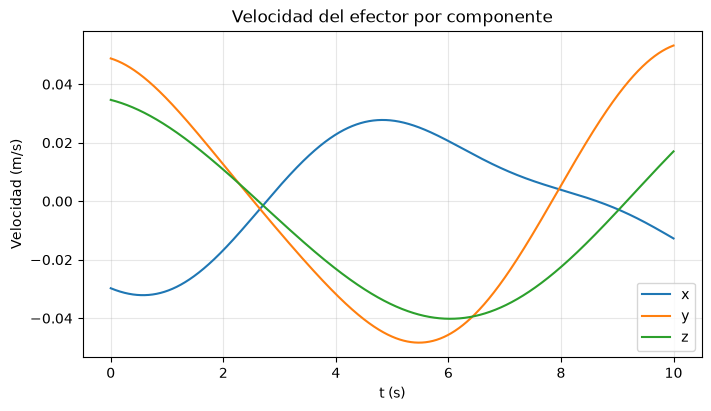

In [6]:
def prescribed_motion(t):
    angles = np.column_stack([
        0.3 + 0.2 * np.sin(0.6*t),
        0.7 + 0.15 * np.sin(0.5*t),
        -0.8 + 0.1 * np.cos(0.4*t),
    ])
    rates = np.column_stack([0.12*np.cos(0.6*t), 0.075*np.cos(0.5*t), -0.04*np.sin(0.4*t)])
    return angles, rates

maximum_errors = []
for dt in [0.02, 0.01, 0.005]:
    t = np.linspace(0, 10, round(10 / dt) + 1)
    angles, rates = prescribed_motion(t)
    positions = np.array([position(row) for row in angles])
    velocities = np.array([linear_jacobian(row) @ rate for row, rate in zip(angles, rates)])
    numeric_velocity = (positions[2:] - positions[:-2]) / (2 * dt)
    error = np.linalg.norm(velocities[1:-1] - numeric_velocity, axis=1)
    maximum_errors.append(error.max())
    print(f"dt={dt:.3f} s: error máximo={error.max():.3e} m/s")
assert np.all(np.array(maximum_errors) < 1e-5)
assert 3.9 < maximum_errors[0] / maximum_errors[1] < 4.1
assert 3.9 < maximum_errors[1] / maximum_errors[2] < 4.1

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(t, velocities)
ax.set(xlabel="t (s)", ylabel="Velocidad (m/s)", title="Velocidad del efector por componente")
ax.legend(["x", "y", "z"])
ax.grid(alpha=0.3)
plt.show()

## Lectura y ejercicio

Con paso 0.01 s el error máximo debe estar cerca de 3.99e-7 m/s. Dividir el paso por dos reduce el error aproximadamente cuatro veces: coincide con el orden de la diferencia central en este régimen. Un paso excesivamente pequeño puede aumentar el error de redondeo.

Probar `dq=[1,0,0]`, `[0,1,0]` y `[0,0,1]`: cada resultado es una columna de `JL`. **Siguiente:** entender cuándo las columnas dejan de aportar direcciones independientes en [singularidades](../singularities/README.md).